# 01 · Data Preparation and Exploratory Analysis

**PhilGEPS procurement-failure risk · Notebook 1 of 3**
**Data:** PhilGEPS 1.5 and PhilGEPS 2.0 (2026 only), cleaned by `00_data_cleaning.ipynb` into `data/raw/cleaned_data/PhilGeps_Cleaned.csv` and harmonised by `scripts/harmonise_cleaned.py` into `data/processed/philgeps_cleaned.parquet`.
**Study window:** 2023 Q1 – 2026 Q2. The 2026 Q3 files are left out.
**Scope:** Public Bidding (called *Competitive Bidding (Public Bidding)* in PhilGEPS 2.0).

## Business question

Using only information available when a procurement notice is published, **how likely is it that the procurement fails**, ending in a `Failed` bidding or a `Cancelled` notice instead of an award?

The output is a **procurement-failure risk score per notice**. It supports risk screening and review prioritisation by agencies, oversight bodies and analysts. It is not a model of whether a particular supplier will win, and it does not recommend which bids suppliers should pursue.

## Where this notebook sits

This series re-runs the analytical roadmap of `LT8-ML_Govt_Bidding_Documented.ipynb` on the expanded, merged dataset. LT8 remains the record of the original 14-file run.

| Roadmap step | Notebook |
|---|---|
| 0. Data cleaning (initial process) | `00_data_cleaning.ipynb` → cleaned CSV; `scripts/harmonise_cleaned.py` → Parquet |
| 1. Source preparation | **01** (this notebook), Phase 1 |
| 2. Initial EDA | **01**, Phase 2 |
| 3. Data-quality investigation | **01**, Phase 3 |
| 4. Consolidation | **01**, Phase 4 |
| 5. Bid-level modelling table | **01**, Phase 5 → writes `data/processed/bids_public_bidding.parquet` |
| 6. Modelling | `02_modeling.ipynb` |
| 7. Robustness diagnostics | `03_diagnostics_and_interpretation.ipynb` |
| 8. Business interpretation | `03_diagnostics_and_interpretation.ipynb` |
| 9. Findings and limitations | `03_diagnostics_and_interpretation.ipynb` |

## Reviewer questions answered here

- **Q2. Are all features available when the notice is published?** §5.6 classifies every field by when it becomes known.
- **Q3. How are ongoing, cancelled and closed bids handled?** §5.2 defines the outcome rule: `Failed` or `Cancelled` = 1, `Awarded` = 0, `Closed` bids removed.
- **Q4. How many observations, and what is the awarded/failed split?** §5.7.

## How to run

From the repository root: `git lfs pull`, then produce `data/raw/cleaned_data/PhilGeps_Cleaned.csv` with `notebooks/00_data_cleaning.ipynb` (or copy the delivered file there), then run `python scripts/harmonise_cleaned.py`. Then run this notebook top to bottom. It reads the harmonised Parquet file, plus the raw CSVs for the source checks in Phase 1 and Phase 3. Peak memory is about 3 GB.

In [1]:
import hashlib
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display

import procurement_failure as pf

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

print("Repository root:", pf.ROOT)
print("Main dataset:", pf.CLEANED, "| exists:", pf.CLEANED.exists())
if not pf.CLEANED.exists():
    raise FileNotFoundError("Run notebooks/00_data_cleaning.ipynb, then `python scripts/harmonise_cleaned.py` from the repository root.")

Repository root: C:\Users\Deborah Argayosa\Documents\GitHub\philgeps-ml-project
Main dataset: C:\Users\Deborah Argayosa\Documents\GitHub\philgeps-ml-project\data\processed\philgeps_cleaned.parquet | exists: True


## Phase 1. Source preparation

### 1.1 Raw file inventory

`data/raw/` holds 30 quarterly CSVs. The file name gives the system and quarter: `<system>_<year>_Q<quarter>.csv`. The `2.0_2023_*` to `2.0_2025_*` files were found to be byte-for-byte copies of the matching `1.5_*` files. PhilGEPS 2.0 only went live in 2026, so these "2.0" files are 1.5 exports saved under a 2.0 name. The cell verifies this with an MD5 checksum of every pair. Notebook 00 reads them too; because they are exact copies, its duplicate-removal step drops their rows, so 2023–2025 is not double-counted. The two 2026 Q3 files (`1.5_2026_Q3`, `2.0_2026_Q3`) fall after the study window (2023 Q1 to 2026 Q2) and are not read.

In [2]:
def md5(path, block=1 << 24):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while chunk := f.read(block):
            h.update(chunk)
    return h.hexdigest()

rows = []
for f in sorted(pf.RAW.glob("*.csv")):
    system, year, quarter = f.stem.split("_")
    rows.append({"File": f.name, "System": system, "Year": int(year), "Quarter": quarter,
                 "Size (MB)": round(f.stat().st_size / 1e6, 1)})
inventory = pd.DataFrame(rows)

# Verify the duplicate claim with full checksums.
dup_check = []
for f in inventory.loc[(inventory.System == "2.0") & (inventory.Year < 2026), "File"]:
    twin = "1.5" + f[3:]
    same = md5(pf.RAW / f) == md5(pf.RAW / twin)
    dup_check.append({"2.0 file": f, "1.5 file": twin, "Identical (MD5)": same})
dup_check = pd.DataFrame(dup_check)
display(dup_check)

dups = set(dup_check.loc[dup_check["Identical (MD5)"], "2.0 file"])
in_window = (inventory.Year.astype(str) + inventory.Quarter).isin(pf.STUDY_QUARTERS)
inventory["Used"] = np.select([inventory.File.isin(dups), ~in_window],
                              ["read; rows dropped as exact duplicates of the 1.5 file", "skipped: after the 2026 Q2 study window"], "used")
display(inventory)
print(f"Files used: {(inventory.Used == 'used').sum()} | duplicate copies: {len(dups)} | "
      f"skipped, outside the study window: {inventory.Used.str.contains('window').sum()}")

,2.0 file,1.5 file,Identical (MD5)
0,2.0_2023_Q1.csv,1.5_2023_Q1.csv,True
1,2.0_2023_Q2.csv,1.5_2023_Q2.csv,True
2,2.0_2023_Q3.csv,1.5_2023_Q3.csv,True
3,2.0_2023_Q4.csv,1.5_2023_Q4.csv,True
4,2.0_2024_Q1.csv,1.5_2024_Q1.csv,True
5,2.0_2024_Q2.csv,1.5_2024_Q2.csv,True
6,2.0_2024_Q3.csv,1.5_2024_Q3.csv,True
7,2.0_2024_Q4.csv,1.5_2024_Q4.csv,True
8,2.0_2025_Q1.csv,1.5_2025_Q1.csv,True
9,2.0_2025_Q2.csv,1.5_2025_Q2.csv,True


,File,System,Year,Quarter,Size (MB),Used
0,1.5_2023_Q1.csv,1.5,2023,Q1,292.2,used
1,1.5_2023_Q2.csv,1.5,2023,Q2,310.2,used
2,1.5_2023_Q3.csv,1.5,2023,Q3,323.7,used
3,1.5_2023_Q4.csv,1.5,2023,Q4,328.0,used
4,1.5_2024_Q1.csv,1.5,2024,Q1,321.2,used
5,1.5_2024_Q2.csv,1.5,2024,Q2,345.4,used
6,1.5_2024_Q3.csv,1.5,2024,Q3,340.5,used
7,1.5_2024_Q4.csv,1.5,2024,Q4,373.1,used
8,1.5_2025_Q1.csv,1.5,2025,Q1,337.1,used
9,1.5_2025_Q2.csv,1.5,2025,Q2,263.9,used


Files used: 16 | duplicate copies: 12 | skipped, outside the study window: 2


### 1.2 Raw layouts

The used files come in four formats. Notebook 00 and `scripts/harmonise_cleaned.py` map them all onto the 1.5 (2023–2025) column names. The check below reads the first line and the first 20 MB of each file to report its delimiter, encoding and column count.

In [3]:
def describe_raw(path):
    head = open(path, "rb").read(20_000_000)
    bom = head.startswith(b"\xef\xbb\xbf")
    try:
        head.decode("utf-8")
        encoding = "UTF-8" + (" with BOM" if bom else "")
    except UnicodeDecodeError as e:
        # A cut multi-byte character at the 20 MB boundary is still UTF-8.
        encoding = "UTF-8" if e.start > len(head) - 4 else "Windows-1252"
    first = head.split(b"\n", 1)[0]
    delim = "tab" if first.count(b"\t") > first.count(b",") else "comma"
    header = pd.read_csv(path, nrows=0, sep="\t" if delim == "tab" else ",",
                         encoding="utf-8-sig" if encoding.startswith("UTF") else "cp1252").columns
    return delim, encoding, len(header), "Solicitation No." in header, "Lot Type" in header

layout_rows = []
for f in inventory.loc[inventory.Used == "used", "File"]:
    delim, enc, ncol, has_solicitation, has_lot = describe_raw(pf.RAW / f)
    layout = ("2.0 (2026)" if has_lot else "1.5 (2026 layout)" if has_solicitation
              else "1.5 2025 Q4 (tab, shifted)" if delim == "tab" else "1.5 (2023–2025 layout)")
    layout_rows.append({"File": f, "Layout": layout, "Delimiter": delim, "Encoding": enc, "Columns": ncol})
layouts = pd.DataFrame(layout_rows)
display(layouts)
display(layouts.groupby(["Layout", "Delimiter", "Encoding", "Columns"]).size().rename("Files").reset_index())

,File,Layout,Delimiter,Encoding,Columns
0,1.5_2023_Q1.csv,1.5 (2023–2025 layout),comma,UTF-8 with BOM,46
1,1.5_2023_Q2.csv,1.5 (2023–2025 layout),comma,UTF-8 with BOM,46
2,1.5_2023_Q3.csv,1.5 (2023–2025 layout),comma,UTF-8 with BOM,46
3,1.5_2023_Q4.csv,1.5 (2023–2025 layout),comma,UTF-8 with BOM,46
4,1.5_2024_Q1.csv,1.5 (2023–2025 layout),comma,UTF-8 with BOM,46
5,1.5_2024_Q2.csv,1.5 (2023–2025 layout),comma,UTF-8 with BOM,46
6,1.5_2024_Q3.csv,1.5 (2023–2025 layout),comma,UTF-8 with BOM,46
7,1.5_2024_Q4.csv,1.5 (2023–2025 layout),comma,UTF-8 with BOM,46
8,1.5_2025_Q1.csv,1.5 (2023–2025 layout),comma,UTF-8 with BOM,46
9,1.5_2025_Q2.csv,1.5 (2023–2025 layout),comma,UTF-8 with BOM,46


,Layout,Delimiter,Encoding,Columns,Files
0,1.5 (2023–2025 layout),comma,UTF-8 with BOM,46,11
1,1.5 (2026 layout),comma,Windows-1252,47,2
2,"1.5 2025 Q4 (tab, shifted)",tab,Windows-1252,46,1
3,2.0 (2026),comma,UTF-8,45,2


### 1.3 The cleaned dataset

`00_data_cleaning.ipynb` reads the 28 files in the window, repairs the 2025 Q4 column shift, renames the 2.0 headers, merges everything, and drops exact duplicate rows and `Closed` rows. `scripts/harmonise_cleaned.py` then adds `Source System` (PhilGEPS 2.0 rows are the ones with `Lot Type` filled), merges the columns that carry the 2026 names (`Procurement Category` → `Business Category`, `Source of Funds` → `Funding Source`, `Delivery Period` → `Contract Duration`, ...), harmonises labels, and parses dates and amounts. The result has one row per bid line item. The raw files are not modified.

Duplicate removal keeps one copy of rows that appear in several files, so the file of origin is not kept. Periods are taken from the publication date instead.

In [4]:
pfile = pq.ParquetFile(pf.CLEANED)
print(f"Rows: {pfile.metadata.num_rows:,} | Columns: {len(pfile.schema_arrow.names)} | "
      f"Size: {pf.CLEANED.stat().st_size / 1e6:.0f} MB")

overview = pq.read_table(pf.CLEANED, columns=["Source System", "Bid Notice Status", "Published Date"]).to_pandas()
overview["Published quarter"] = overview["Published Date"].dt.to_period("Q").astype(str)
display(overview.groupby(["Published quarter", "Source System"]).size().unstack(fill_value=0))
print("Line items by system:", overview["Source System"].value_counts().to_dict())
print("Bid Notice Status (line items):", overview["Bid Notice Status"].value_counts(dropna=False).to_dict())
del overview

print("\nColumns:")
print(", ".join(pfile.schema_arrow.names))

Rows: 2,093,210 | Columns: 51 | Size: 223 MB


Source System,1.5,2.0
Published quarter,,
2023Q1,148589,0
2023Q2,158417,0
2023Q3,162095,0
2023Q4,168878,0
2024Q1,165902,0
2024Q2,179098,0
2024Q3,174033,0
2024Q4,189776,0
2025Q1,169890,0


Line items by system: {'1.5': 2059090, '2.0': 34120}
Bid Notice Status (line items): {'Awarded': 1742602, 'Failed': 161797, 'Cancelled': 158747, 'Active': 28949, 'Shortlisted': 937, 'Concluded': 175, nan: 3}

Columns:
Source System, Procuring Entity (PE), Region, Province, City/Municipality, Government Branch, PE Organization Type, PE Organization Type (Grouped), Bid Reference No., Solicitation No., Notice Title, Classification, Procurement Mode, Procurement Mode (Grouped), Business Category, Funding Source, Funding Instrument, Trade Agreement, Approved Budget of the Contract, Published Date, Closing Date, Area of Delivery, Contract Duration, Calendar Type, Lot Type, Line Item No, Item Name, Item Description, Quantity, UOM, Item Budget, Bid Notice Status, Award Reference No., Award Title, UNSPSC Code, UNSPSC Description, Published Date(Award), Award Date, Contract Amount, Award Notice Status, Notice to Proceed Date, Contract Effectivity Date, Contract End Date, Awardee OrgID, Awardee O

## Phase 2. Initial exploratory analysis

### 2.1 Procurement modes and the choice of Public Bidding

Procurement mode labels changed between the systems. For example, `Negotiated Procurement - Small Value Procurement (Sec. 53.9)` in 1.5 corresponds to `Small Value Procurement` in 2.0, and `Public Bidding` corresponds to `Competitive Bidding (Public Bidding)`. The harmonisation script adds `Procurement Mode (Grouped)`, which strips section numbers and maps the 2.0 names onto the 1.5 names.

Public Bidding is the modelling scope. It is the main competitive mode, and a *failed bidding* is a formally defined outcome only in competitive bidding. Small-value procurement and shopping are high-volume but follow different rules.

Source System,1.5,2.0,Total bids,Share (%)
Procurement Mode (Grouped),,,,
Small Value Procurement,738554,8264,746818,49.47
Public Bidding,621529,8494,630023,41.73
Shopping - Ordinary/Regular Office Supplies & Equipment,112282,3,112285,7.44
Negotiated Procurement - Two Failed Biddings,18544,82,18626,1.23
Negotiated Procurement - NGO Participation,859,1,860,0.06
International Competitive Bidding,767,2,769,0.05
Negotiated Procurement - Lease of Real Property and Venue,1,84,85,0.01
Limited Source Bidding,54,2,56,0.00
Direct Acquisition,0,16,16,0.00


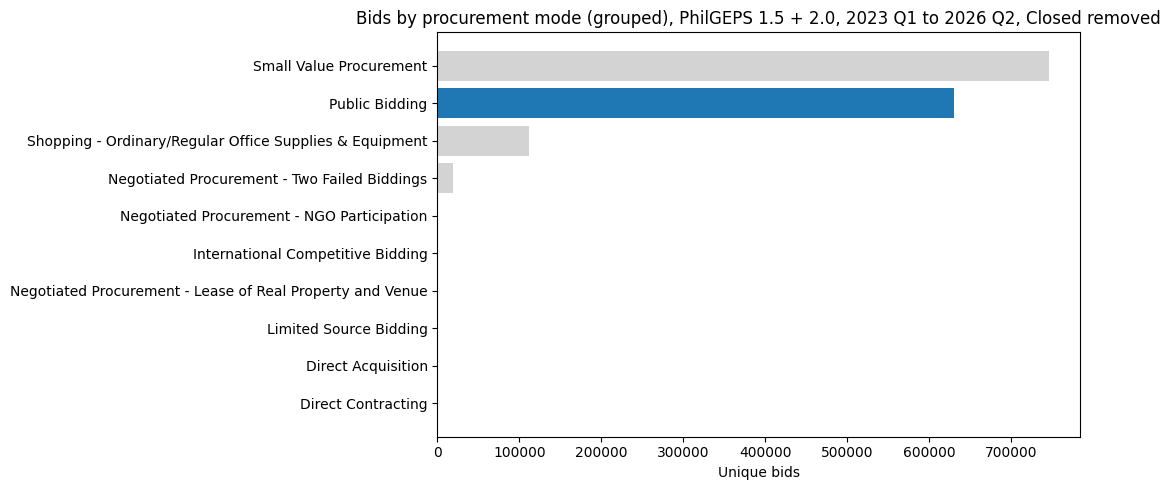

In [5]:
modes = pq.read_table(pf.CLEANED, columns=["Source System", "Procurement Mode (Grouped)", "Bid Reference No."]).to_pandas()
mode_bids = (modes.drop_duplicates(["Source System", "Bid Reference No.", "Procurement Mode (Grouped)"])
             .groupby(["Procurement Mode (Grouped)", "Source System"], observed=True).size().unstack(fill_value=0))
mode_bids["Total bids"] = mode_bids.sum(axis=1)
mode_bids = mode_bids.sort_values("Total bids", ascending=False)
mode_bids["Share (%)"] = (mode_bids["Total bids"] / mode_bids["Total bids"].sum() * 100).round(2)
display(mode_bids.head(15))
del modes

top = mode_bids.head(10)["Total bids"].sort_values()
plt.figure(figsize=(11, 5))
plt.barh(top.index, top.values, color=["tab:blue" if i == "Public Bidding" else "lightgray" for i in top.index])
plt.xlabel("Unique bids")
plt.title("Bids by procurement mode (grouped), PhilGEPS 1.5 + 2.0, 2023 Q1 to 2026 Q2, Closed removed")
plt.tight_layout(); plt.show()

### 2.2 Load Public Bidding line items

From here on, only Public Bidding line items from the study window (2023 Q1 to 2026 Q2) are used. The filter is applied while reading the Parquet file, so only those rows are loaded.

In [6]:
items = pf.load_public_bidding_items(pf.ITEM_COLUMNS + ["Award Notice Status", "Procurement Mode"])
print(f"Public Bidding line items: {len(items):,}")
print(f"Unique bids: {items.groupby(pf.KEY, observed=True).ngroups:,}")
print("\nRaw procurement-mode labels mapped to Public Bidding:")
display(items.groupby(["Source System", "Procurement Mode"], observed=True).size().rename("Line items").reset_index())

Public Bidding line items: 802,790


Unique bids: 630,023

Raw procurement-mode labels mapped to Public Bidding:


,Source System,Procurement Mode,Line items
0,1.5,Public Bidding,787856
1,2.0,Competitive Bidding (Public Bidding),14934


### 2.3 Outcome statuses

`Bid Notice Status` is the outcome of the notice: `Awarded`, `Failed`, `Closed`, `Cancelled`, `Active` and `Shortlisted` in 1.5. PhilGEPS 2.0 uses `Published`, `CANCEL_APPROVED` and `CONCLUDED`, which the harmonisation script maps to `Active`, `Cancelled` and `Concluded`.

`Award Notice Status` describes the award notice, not the bidding outcome, and its vocabulary differs between systems: `Posted`/`Updated` in 1.5, `Published`/`NTP Issued` in 2.0. The cross-tab shows how the two fields relate. Some `Closed` notices already carry an award notice. This is why the outcome is taken from `Bid Notice Status` alone: `Awarded`, `Failed` and `Cancelled` are used as outcomes, and `Closed` notices are removed (§5.2).

In [7]:
for system in ["1.5", "2.0"]:
    sub = items[items["Source System"] == system]
    ct = pd.crosstab(sub["Bid Notice Status"].astype("string").fillna("(missing)"),
                     sub["Award Notice Status"].astype("string").fillna("(no award notice)"))
    print(f"PhilGEPS {system}: Bid Notice Status (rows) x Award Notice Status (columns), line items")
    display(ct)

PhilGEPS 1.5: Bid Notice Status (rows) x Award Notice Status (columns), line items


Award Notice Status,(no award notice),Cancelled,Posted,Updated
Bid Notice Status,,,,
Active,20398,0,0,0
Awarded,75891,2016,66292,472690
Cancelled,70264,0,0,0
Failed,79491,0,0,1
Shortlisted,812,0,0,1


PhilGEPS 2.0: Bid Notice Status (rows) x Award Notice Status (columns), line items


Award Notice Status,(no award notice),Cancelled,DRAFT_APR,NTP Issued,Published
Bid Notice Status,,,,,
Active,7,0,0,0,0
Awarded,3724,32,13,3089,3014
Cancelled,2,0,0,5,0
Concluded,40,0,0,0,0
Failed,4973,11,0,11,13


### 2.4 Unit of observation

One bid (`Bid Reference No.`) can have many line items. If line items were modelled as separate observations, large multi-item procurements would carry much more weight, and near-identical rows from the same bid could land in both the training and the test set. The modelling unit is therefore **one bid**. Bid references are numbered independently in each system: 1.5 uses 7–8 digit numbers, 2.0 uses short ones. So the key is (`Source System`, `Bid Reference No.`).

Exact duplicate line items (identical in every column) were removed in notebook 00. This cell confirms that none remain, by hashing each row while streaming the file in batches.

In [8]:
per_bid = items.groupby(pf.KEY, observed=True).size()
print("Line items per bid:")
display(per_bid.describe(percentiles=[.5, .75, .9, .99]).round(1).to_frame("line items").T)
print(f"Bids with a single line item: {(per_bid == 1).mean() * 100:.1f}%")
print("Most repeated bids:")
display(per_bid.sort_values(ascending=False).head(5).rename("line items").reset_index())

# Exact duplicate line items across all columns.
hashes = []
reader = pq.ParquetFile(pf.CLEANED)
for batch in reader.iter_batches(batch_size=200_000):
    frame = batch.to_pandas()
    frame = frame[frame["Procurement Mode (Grouped)"] == "Public Bidding"]
    hashes.append(pd.util.hash_pandas_object(frame, index=False).to_numpy())
hashes = np.concatenate(hashes)
n_dup = len(hashes) - len(np.unique(hashes))
print(f"\nExact duplicate Public Bidding line items remaining: {n_dup:,} of {len(hashes):,}")
del hashes

Line items per bid:


,count,mean,std,min,50%,75%,90%,99%,max
line items,630023.0,1.3,3.8,1.0,1.0,1.0,1.0,7.0,498.0


Bids with a single line item: 95.9%
Most repeated bids:


,Source System,Bid Reference No.,line items
0,1.5,12435513,498
1,1.5,10690092,421
2,1.5,12898148,420
3,1.5,12386800,414
4,1.5,12912508,385



Exact duplicate Public Bidding line items remaining: 0 of 802,790


## Phase 3. Data-quality investigation

### 3.1 The 2025 Q4 column shift

`1.5_2025_Q4.csv` has 46 fields like the other 1.5 files, but the `Calendar Type` value is missing and every later value sits one column to the left. Read naively, `Bid Notice Status` holds award reference numbers and the statuses appear under `Item Budget`. A header count cannot catch this; the check has to look at the values. Notebook 00 drops the `Calendar Type` name so every later name moves one position to the right, and drops the then-empty trailing column. This cell confirms the problem in the raw file (including that the trailing column is empty) and checks the repair in the cleaned file.

In [9]:
raw_q4 = pd.read_csv(pf.RAW / "1.5_2025_Q4.csv", sep="\t", encoding="cp1252", encoding_errors="replace",
                     dtype=str, na_values=["NULL"], nrows=200_000)
print("Raw file read naively (first 200,000 rows):")
print("  'Bid Notice Status' column, top values:", raw_q4["Bid Notice Status"].value_counts(dropna=False).head(4).to_dict())
print("  'Item Budget' column, top values:      ", raw_q4["Item Budget"].value_counts(dropna=False).head(6).to_dict())
print("  last column all empty:", raw_q4.iloc[:, -1].isna().all())
del raw_q4

chk = pq.read_table(pf.CLEANED, columns=["Bid Notice Status", "Item Budget", "Calendar Type", "Published Date"]).to_pandas()
q4 = chk[chk["Published Date"].dt.to_period("Q") == "2025Q4"]
print("\nCleaned file after repair (line items published in 2025 Q4):")
print("  Bid Notice Status:", q4["Bid Notice Status"].value_counts(dropna=False).to_dict())
print("  Item Budget numeric share:", round(q4["Item Budget"].notna().mean(), 4))
print("  Calendar Type:", q4["Calendar Type"].value_counts(dropna=False).to_dict())
print("Bid Notice Status values in the whole cleaned file:", sorted(chk["Bid Notice Status"].dropna().unique()))
del q4, chk

Raw file read naively (first 200,000 rows):
  'Bid Notice Status' column, top values: {nan: 198721, '5882412': 150, '5909965': 64, '5857006': 60}
  'Item Budget' column, top values:       {'Closed': 144281, 'Awarded': 45669, 'Cancelled': 5777, 'Failed': 4006, 'Active': 246, 'Shortlisted': 21}
  last column all empty: True

Cleaned file after repair (line items published in 2025 Q4):
  Bid Notice Status: {'Awarded': 60156, 'Cancelled': 9815, 'Failed': 6048, 'Active': 5773, 'Shortlisted': 46}
  Item Budget numeric share: 0.8516
  Calendar Type: {'Day/s': 75088, nan: 5629, 'Month/s': 729, 'Year/s': 392}


Bid Notice Status values in the whole cleaned file: ['Active', 'Awarded', 'Cancelled', 'Concluded', 'Failed', 'Shortlisted']


### 3.2 Harmonised labels

These fields and labels differ between the layouts only in naming or spelling. Notebook 00 renames the 2.0 headers it lists; `scripts/harmonise_cleaned.py` does the rest:

- **Column names (2026 layouts):** `Procurement Category` → `Business Category`, `Source of Funds` → `Funding Source`, `Applicable Procurement Rules` → `Trade Agreement`, `Area of Delivery/Project Location` → `Area of Delivery`, `Delivery Period` → `Contract Duration`, `Item/Lot Name.1` → `UNSPSC Description`, `Award Notice Status (Item)` → `Award Notice Status`.

- **Bid Notice Status (2.0):** `Published` → `Active`, `CANCEL_APPROVED` → `Cancelled`, `CONCLUDED` → `Concluded`.
- **Classification (2.0):** `Civil Works - Infra Project` → `Civil Works`.
- **Region (2.0):** upper-case variants such as `REGION IX` → `Region IX`, and `ARMM` → `BARMM`.
- **Procurement mode:** grouped as described in §2.1.
- **Contract duration:** `30 Day/s` and `1 years` are split into a number and a unit.

The raw 2.0 values are read directly from the 2.0 CSVs below, to show what the mapping changed.

In [10]:
raw20 = pd.concat([pd.read_csv(pf.RAW / f"2.0_2026_Q{q}.csv", dtype=str, na_values=["NULL"],
                               usecols=["Bid Notice Status", "Classification", "Region"]) for q in (1, 2)])
for col in ["Bid Notice Status", "Classification"]:
    print(f"Raw PhilGEPS 2.0 '{col}':", raw20[col].value_counts(dropna=False).to_dict())
regions_15 = set(items.loc[items["Source System"] == "1.5", "Region"].dropna().astype(str))
raw_regions = raw20["Region"].dropna()
odd = raw_regions[~raw_regions.isin(regions_15)].value_counts()
print("Raw 2.0 Region values not spelled as in 1.5 (line items):", odd.to_dict())
print("Region values in the combined 2.0 rows that are still not in the 1.5 list:",
      sorted(set(items.loc[items["Source System"] == "2.0", "Region"].dropna().astype(str)) - regions_15))
del raw20

Raw PhilGEPS 2.0 'Bid Notice Status': {'Closed': 31400, 'Awarded': 24202, 'Failed': 10471, 'CONCLUDED': 175, 'CANCEL_APPROVED': 11, 'Published': 7}
Raw PhilGEPS 2.0 'Classification': {'Goods': 55924, 'Civil Works - Infra Project': 7001, 'Goods - General Support Services': 2983, 'Consulting Services': 358}


Raw 2.0 Region values not spelled as in 1.5 (line items): {'CARAGA': 74, 'ARMM': 50, 'REGION IV-A': 9, 'REGION I': 4, 'REGION IV-B': 4, 'NEGROS ISLAND REGION': 3, 'REGION XI': 3, 'REGION VI': 2, 'REGION VII': 1, 'REGION V': 1}
Region values in the combined 2.0 rows that are still not in the 1.5 list: []


### 3.3 Vocabularies that are not comparable between systems

`Business Category` and `Funding Source` mean the same thing in both systems, but use different value sets. PhilGEPS 2.0 categories are product-family names (`Office supplies`, `Heavy construction services`). 2.0 funding sources are budget fund codes (`Regular Agency Fund (01000000)`) rather than lenders (`Government of the Philippines (GOP)`). These values are kept as they are, not forced into a mapping. The models therefore see `Source System` as a feature, and the diagnostics in notebook 03 report results separately for each system.

In [11]:
for col in ["Business Category", "Funding Source", "Trade Agreement"]:
    v15 = set(items.loc[items["Source System"] == "1.5", col].dropna().astype(str))
    v20 = set(items.loc[items["Source System"] == "2.0", col].dropna().astype(str))
    print(f"{col}: {len(v15)} values in 1.5, {len(v20)} in 2.0, {len(v15 & v20)} shared")
print("\nTop 2.0 funding sources:", items.loc[items["Source System"] == "2.0", "Funding Source"].value_counts().head(4).to_dict())

Business Category: 168 values in 1.5, 273 in 2.0, 3 shared


Funding Source: 5 values in 1.5, 9 in 2.0, 0 shared


Trade Agreement: 7 values in 1.5, 5 in 2.0, 5 shared

Top 2.0 funding sources: {'Regular Agency Fund (01000000)': 12672, 'Internally Generated Funds (05000000)': 1144, 'Business Related Funds (06000000)': 500, 'Trust Receipts (07000000)': 270}


### 3.4 Date and amount parsing

The harmonisation script reports values it could not parse; it reported none. The cleaned file keeps no file of origin, so this check looks at the range of publication dates instead. Nearly all should fall in 2023 Q1 to 2026 Q2; notices published just before 2023 can appear in the 2023 Q1 file.

In [12]:
pub_q = items["Published Date"].dt.to_period("Q").astype(str)
in_window = pub_q.isin(pf.STUDY_QUARTERS)
print(f"Missing published dates: {items['Published Date'].isna().sum():,}")
print(f"Line items published within 2023 Q1 to 2026 Q2: {in_window.mean() * 100:.2f}%")
outside = pub_q[~in_window & items["Published Date"].notna()].value_counts().sort_index()
display(outside.rename("Line items published outside the window").to_frame())

Missing published dates: 0
Line items published within 2023 Q1 to 2026 Q2: 100.00%


,Line items published outside the window
Published Date,


## Phase 4. Consolidation

Public Bidding line items and unique bids by publication quarter and system. In 2026 both systems ran side by side with **separate notices**: no bid reference appears in both. The 1.5 exports carry most of the 2026 volume.

,line_items (1.5),line_items (2.0),bids (1.5),bids (2.0)
Published quarter,,,,
2023Q1,60398,0,46540,0
2023Q2,63990,0,50134,0
2023Q3,61505,0,48334,0
2023Q4,71934,0,54574,0
2024Q1,65392,0,50375,0
2024Q2,69077,0,53245,0
2024Q3,65847,0,52126,0
2024Q4,82300,0,65635,0
2025Q1,67332,0,55809,0


Total: 802,790 line items, 630,023 bids


Bid references present in both systems: 0


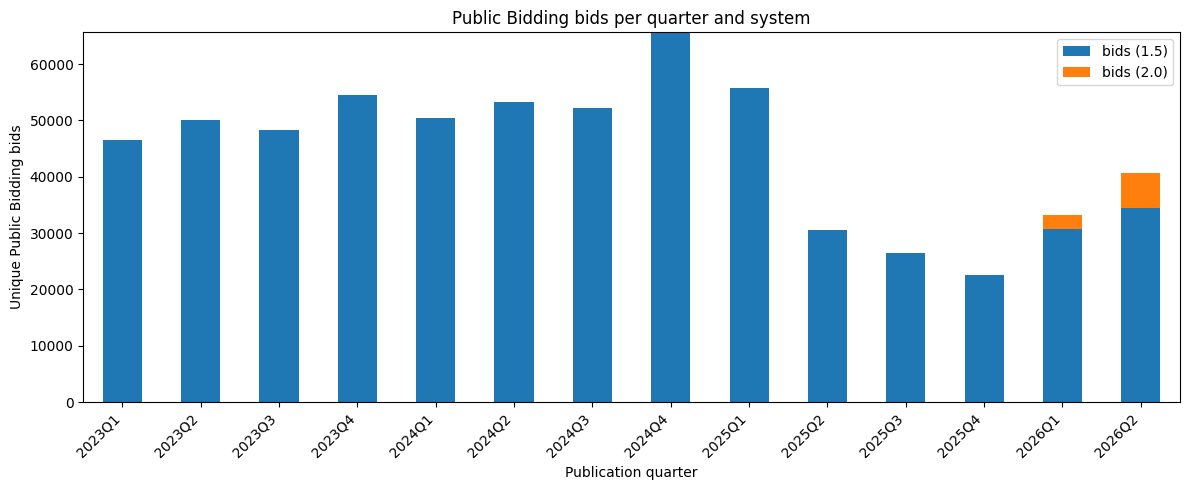

In [13]:
published_quarter = items["Published Date"].dt.to_period("Q").astype(str).rename("Published quarter")
consol = items.groupby([published_quarter, items["Source System"]], observed=True).agg(
    line_items=("Bid Notice Status", "size"),
    bids=("Bid Reference No.", "nunique"),
).unstack("Source System", fill_value=0)
consol.columns = [f"{a} ({b})" for a, b in consol.columns]
display(consol)
print(f"Total: {len(items):,} line items, {items.groupby(pf.KEY, observed=True).ngroups:,} bids")

shared = set(items.loc[items["Source System"] == "1.5", "Bid Reference No."]) & set(items.loc[items["Source System"] == "2.0", "Bid Reference No."])
print(f"Bid references present in both systems: {len(shared)}")

ax = consol[[c for c in consol.columns if c.startswith("bids")]].plot(kind="bar", stacked=True, figsize=(12, 5))
ax.set_ylabel("Unique Public Bidding bids"); ax.set_xlabel("Publication quarter")
ax.set_title("Public Bidding bids per quarter and system")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

## Phase 5. Bid-level modelling table

### 5.1 Build one row per bid

`pf.build_bid_table` aggregates line items to one row per bid. It:

1. Assigns one status per bid. A bid takes a status only when **all** its line items have that status; otherwise it is `Conflicting`. `Closed` line items were removed in notebook 00; any `Closed` bid left would be dropped here.
2. Takes the approved budget, publication date, closing date, contract duration and category fields per bid, and counts how many distinct values each field has within the bid (the *version count*).
3. **Excludes** bids that cannot be described consistently: missing or non-positive approved budget, more than one approved budget, more than one publication date, or more than one `Business Category`, `Region` or `Classification`. These go to an exceptions log with the reason.
4. Where a bid has several funding sources or funding instruments (mostly multi-lot bids), uses the most frequent one and sets the flag `multi_funding_source`, rather than dropping the bid.
5. Sets impossible bidding windows (negative or over a year) and contract durations over ten years to missing, rather than dropping the bid.
6. Adds the **re-advertisement history** of each notice. Notices with the same procuring entity, title (normalised) and approved budget form a `notice_group`. `n_prior_attempts` counts the notices of the group published strictly earlier, and `previous_attempt` gives the outcome of the latest of them (`Failed`, `Cancelled`, `Awarded`, `No outcome yet`) or `First notice`. Both use only notices published before the bid, so they are known at publication (§5.8).
7. Flags bids published in **2025 Q3–Q4** as outside the modelling scope (`in_model_scope` = False). Their outcomes are incomplete in the PhilGEPS 1.5 exports (§5.3). They stay in the table for the descriptive checks.

In [14]:
n_closed = int(items["Bid Notice Status"].isin(pf.REMOVED_STATUSES).sum())
print(f"Closed line items left in the cleaned file: {n_closed:,} (removed in notebook 00)")

bids, exceptions = pf.build_bid_table(items)
print(f"Bids in the modelling table: {len(bids):,}")
print(f"Bids excluded for data quality: {len(exceptions):,}")
display(exceptions["reason"].value_counts().rename("Bids").to_frame())
print("Excluded bids by status:", exceptions["status"].value_counts().to_dict())
exceptions.to_csv(pf.EXCEPTIONS, index=False)
print("Exceptions log written to", pf.EXCEPTIONS.relative_to(pf.ROOT))

Closed line items left in the cleaned file: 0 (removed in notebook 00)


Bids in the modelling table: 629,921
Bids excluded for data quality: 102


,Bids
reason,
non-positive approved budget,100
more than one approved budget; more than one Business Category; more than one Region,1
more than one approved budget; more than one published date; more than one Business Category; more than one Region; more than one Classification,1


Excluded bids by status: {'Awarded': 48, 'Cancelled': 36, 'Failed': 13, 'Active': 5}
Exceptions log written to data\processed\bids_public_bidding_exceptions.csv


### 5.2 Outcome definition and handling of every status (reviewer Q3)

| Bid status | Meaning | Main target `Target_Failed` | Sensitivity target `Target_Failed_Only` |
|---|---|---|---|
| `Awarded` | contract awarded | **0** | 0 |
| `Failed` | failed bidding declared | **1** | 1 |
| `Cancelled` | notice withdrawn by the agency | **1** | unlabelled |
| `Closed` | submission deadline passed, no outcome posted | **removed from the data** | removed |
| `Active` / 2.0 `Published` | still open | unlabelled, excluded | unlabelled |
| `Shortlisted` | in evaluation | unlabelled, excluded | unlabelled |
| `Concluded` (2.0 only) | process ended, outcome not stated | unlabelled, excluded | unlabelled |
| `Conflicting` | line items disagree | unlabelled, excluded | unlabelled |

**Procurement failure** means the notice did not lead to a contract: either the bidding was declared `Failed`, or the agency `Cancelled` the notice. Both count as 1; `Awarded` counts as 0. `Closed` bids have no posted outcome, so they are removed in notebook 00 and do not appear in any later count. Ongoing notices stay in the table as unlabelled, for the coverage checks, and are not used for modelling. Notebook 02 tests how much the results change if only `Failed` counts as failure.

In [15]:
def status_table(frame):
    t = pd.crosstab(frame["status"], frame["Source System"], margins=True, margins_name="All")
    t = t.reindex([s for s in pf.STATUS_ORDER if s in t.index] + ["All"])
    t["Share (%)"] = (t["All"] / len(frame) * 100).round(2)
    t["Target_Failed"] = t.index.map({"Awarded": "0", "Failed": "1", "Cancelled": "1"}).fillna("excluded")
    t.loc["All", "Target_Failed"] = ""
    return t

display(status_table(bids))

Source System,1.5,2.0,All,Share (%),Target_Failed
status,,,,,
Awarded,487059,5224,492283,78.15,0
Failed,62997,3253,66250,10.52,1
Cancelled,56864,1,56865,9.03,1
Active,13809,7,13816,2.19,excluded
Shortlisted,700,0,700,0.11,excluded
Concluded,0,7,7,0.00,excluded
All,621429,8492,629921,100.00,


### 5.3 Label coverage and failure rate by quarter

*Label coverage* is the share of the remaining bids (Closed removed) with a final `Awarded`, `Failed` or `Cancelled` status. The bids still unlabelled are mostly `Active`. The failure rate is conditional on an outcome having been posted. It is not the failure rate of all published notices: the removed `Closed` bids are also notices without a posted outcome.

**2025 Q3–Q4 are excluded from modelling.** In the PhilGEPS 1.5 exports for these two quarters, award records are largely missing: before `Closed` rows were removed, only 13–16% of bids were `Awarded` (about 45% in other quarters) and 66–71% were `Closed`. Closed rows carry no award details there (2% and 0%, against 14–29% elsewhere). `Cancelled` stays at about 5%, so the labelled bids of these quarters are cancellation-heavy and their failure rate (33–37%) is not comparable with the rest. Re-downloading the files from PhilGEPS gave byte-identical files. The bids are kept in the table for the descriptive tables here and in notebook 03, and notebook 02 §6.11 tests including them.

,,bids,labelled,failed,Label coverage (%),Failure rate among labelled (%)
published_quarter,Source System,,,,,
2023Q1,1.5,46534,46493,8520.0,99.9,18.33
2023Q2,1.5,50129,50080,9866.0,99.9,19.70
2023Q3,1.5,48322,48241,9223.0,99.8,19.12
2023Q4,1.5,54559,54480,9848.0,99.9,18.08
2024Q1,1.5,50363,50315,8363.0,99.9,16.62
2024Q2,1.5,53232,53156,9402.0,99.9,17.69
2024Q3,1.5,52124,52081,9917.0,99.9,19.04
2024Q4,1.5,65621,65540,12046.0,99.9,18.38
2025Q1,1.5,55802,55753,9701.0,99.9,17.40


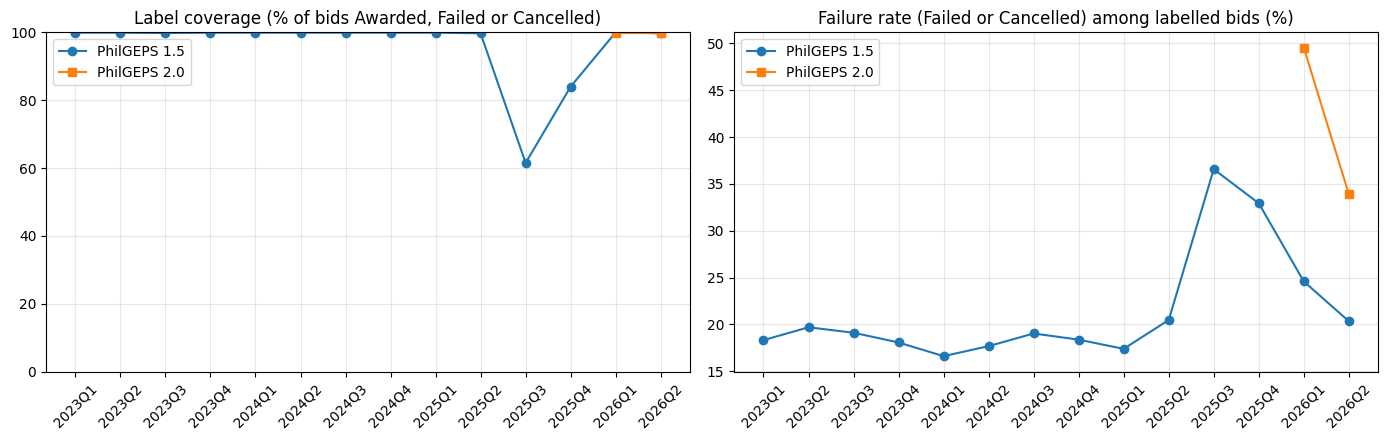

In [16]:
cov = bids.groupby(["published_quarter", "Source System"], observed=True).agg(
    bids=("status", "size"),
    labelled=("Target_Failed", "count"),
    failed=("Target_Failed", "sum"),
)
cov["Label coverage (%)"] = (cov["labelled"] / cov["bids"] * 100).round(1)
cov["Failure rate among labelled (%)"] = (cov["failed"] / cov["labelled"] * 100).round(2)
display(cov)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for system, style in [("1.5", "-o"), ("2.0", "-s")]:
    sub = cov.xs(system, level="Source System")
    axes[0].plot(sub.index.astype(str), sub["Label coverage (%)"], style, label=f"PhilGEPS {system}")
    axes[1].plot(sub.index.astype(str), sub["Failure rate among labelled (%)"], style, label=f"PhilGEPS {system}")
axes[0].set_title("Label coverage (% of bids Awarded, Failed or Cancelled)"); axes[0].set_ylim(0, 100)
axes[1].set_title("Failure rate (Failed or Cancelled) among labelled bids (%)")
for ax in axes:
    ax.tick_params(axis="x", rotation=45); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

### 5.4 Feature completeness and consistency

For each candidate feature, the table shows the share of missing values and the share of bids where line items disagreed (version count above one). High completeness does not guarantee that a field means the same thing across systems; see §3.3.

In [17]:
feature_cols = pf.EXPANDED_NUMERIC + [c for c in pf.EXPANDED_CATEGORICAL if c not in ("Source System",)]
audit = pd.DataFrame({
    "Missing (%)": bids[feature_cols].isna().mean().mul(100).round(2),
    "Distinct values": bids[feature_cols].nunique(),
})
audit["Missing in 1.5 (%)"] = bids.loc[bids["Source System"] == "1.5", feature_cols].isna().mean().mul(100).round(2)
audit["Missing in 2.0 (%)"] = bids.loc[bids["Source System"] == "2.0", feature_cols].isna().mean().mul(100).round(2)
display(audit)
print("Bids flagged with more than one funding source:", int(bids["multi_funding_source"].sum()))

,Missing (%),Distinct values,Missing in 1.5 (%),Missing in 2.0 (%)
log_approved_budget,0.00,284171,0.0,0.00
bidding_window_days,0.00,224,0.0,0.02
log_n_line_items,0.00,194,0.0,0.00
log_contract_duration_days,0.01,718,0.0,0.06
multi_funding_source,0.00,2,0.0,0.00
n_prior_attempts,0.00,53,0.0,0.00
Funding Source,0.00,14,0.0,0.00
Business Category,0.00,438,0.0,0.00
Region,0.00,18,0.0,0.00
published_month,0.00,12,0.0,0.00


Bids flagged with more than one funding source: 152


### 5.5 Budget and bidding-window validation

The approved budget is positive for every retained bid; non-positive budgets were excluded in §5.1. It spans several orders of magnitude, so models use `log(1 + budget)`. The bidding window is the number of days from publication to the closing date. Both are known when the notice is posted.

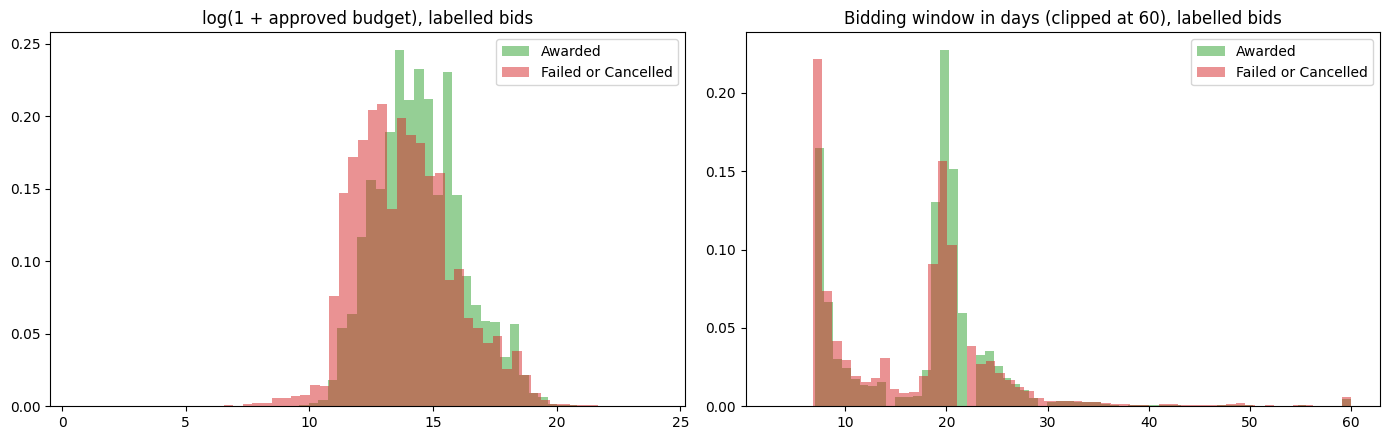

,median approved_budget,median bidding_window_days,median n_line_items
Target_Failed,,,
Awarded,1811300.00,20.0,1.0
Failed or Cancelled,972185.24,19.0,1.0


In [18]:
lab = bids[bids["Target_Failed"].notna()]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for value, name, color in [(0, "Awarded", "tab:green"), (1, "Failed or Cancelled", "tab:red")]:
    s = lab.loc[lab["Target_Failed"] == value]
    axes[0].hist(s["log_approved_budget"], bins=60, alpha=.5, density=True, label=name, color=color)
    axes[1].hist(s["bidding_window_days"].clip(upper=60), bins=60, alpha=.5, density=True, label=name, color=color)
axes[0].set_title("log(1 + approved budget), labelled bids"); axes[0].legend()
axes[1].set_title("Bidding window in days (clipped at 60), labelled bids"); axes[1].legend()
plt.tight_layout(); plt.show()

display(lab.groupby("Target_Failed")[["approved_budget", "bidding_window_days", "n_line_items"]].median()
        .rename(index={0.0: "Awarded", 1.0: "Failed or Cancelled"}).rename(columns=lambda c: f"median {c}"))

### 5.6 Field availability at publication (reviewer Q2)

Every field of the combined dataset is classified by when it becomes known. Only the first group is used as predictors. Award and contract fields are consequences of the outcome and are **excluded**. Identifiers and free text are available at publication but not used in this round.

One caveat cannot be checked from the data. The extracts are final-state snapshots, so a field an agency edited after publication shows its edited value. This is listed as a limitation in notebook 03.

In [19]:
availability = {
    "Available at publication: candidate predictor": [
        "Procuring Entity (PE)", "Region", "Province", "City/Municipality", "Government Branch",
        "PE Organization Type", "PE Organization Type (Grouped)", "Classification", "Procurement Mode",
        "Procurement Mode (Grouped)", "Business Category", "Funding Source", "Funding Instrument",
        "Trade Agreement", "Approved Budget of the Contract", "Published Date", "Closing Date",
        "Area of Delivery", "Contract Duration", "Calendar Type", "Lot Type", "Quantity", "UOM",
        "Item Budget", "UNSPSC Code"],
    "Available at publication: identifier / free text": [
        "Bid Reference No.", "Solicitation No.", "Notice Title", "Line Item No",
        "Item Name", "Item Description", "UNSPSC Description"],
    "Outcome: defines the target": ["Bid Notice Status"],
    "Known only after bidding: excluded": [
        "Award Reference No.", "Award Title", "Published Date(Award)", "Award Date", "Contract Amount",
        "Award Notice Status", "Notice to Proceed Date", "Contract Effectivity Date", "Contract End Date",
        "Awardee OrgID", "Awardee Organization Name", "Country of Awardee", "Region of Awardee",
        "Province of Awardee", "City/Municipality of Awardee", "Awardee Size", "Awardee Joint Venture"],
    "Lineage (added by the harmonisation script)": ["Source System"],
}
used_in = {
    "Approved Budget of the Contract": "original 5 + expanded", "Funding Source": "original 5 + expanded",
    "Business Category": "original 5 + expanded", "Region": "original 5 + expanded",
    "Published Date": "original 5 + expanded (month; expanded adds weekday)",
    "Closing Date": "expanded (bidding window)", "Contract Duration": "expanded", "Calendar Type": "expanded",
    "Classification": "expanded", "PE Organization Type (Grouped)": "expanded", "Government Branch": "expanded",
    "Funding Instrument": "expanded", "Trade Agreement": "expanded", "Lot Type": "expanded",
    "Source System": "expanded", "Bid Reference No.": "expanded (number of line items per bid)",
    "Procuring Entity (PE)": "expanded (re-advertisement history; not an input itself)",
    "Notice Title": "expanded (re-advertisement history; not an input itself)",
}
table = pd.DataFrame([{"Availability": g, "Field": f, "Used in model": used_in.get(f, "")}
                      for g, fs in availability.items() for f in fs])
assert set(table["Field"]) == set(pfile.schema_arrow.names), set(pfile.schema_arrow.names) ^ set(table["Field"])
display(table)

,Availability,Field,Used in model
0,Available at publication: candidate predictor,Procuring Entity (PE),expanded (re-advertisement history; not an input itself)
1,Available at publication: candidate predictor,Region,original 5 + expanded
2,Available at publication: candidate predictor,Province,
3,Available at publication: candidate predictor,City/Municipality,
4,Available at publication: candidate predictor,Government Branch,expanded
5,Available at publication: candidate predictor,PE Organization Type,
6,Available at publication: candidate predictor,PE Organization Type (Grouped),expanded
7,Available at publication: candidate predictor,Classification,expanded
8,Available at publication: candidate predictor,Procurement Mode,
9,Available at publication: candidate predictor,Procurement Mode (Grouped),


### 5.7 Final modelling table and class balance (reviewer Q4)

The modelling population is the labelled bids (`Target_Failed` ∈ {0, 1}) published outside 2025 Q3–Q4 (`in_model_scope`). The full table, including unlabelled and out-of-scope bids, is saved so that notebook 03 can study label coverage and notebook 02 can run the 2025 Q3–Q4 sensitivity check.

In [20]:
lab_all = bids[bids["Target_Failed"].notna()]
lab = lab_all[lab_all["in_model_scope"]]
summary = pd.DataFrame({
    "Bids": [len(bids), len(lab_all), len(lab_all) - len(lab), len(lab), int((lab.Target_Failed == 0).sum()),
             int((lab.Target_Failed == 1).sum()), int((lab.status == "Failed").sum()), int((lab.status == "Cancelled").sum()),
             len(bids) - len(lab_all)],
}, index=["All Public Bidding bids (Closed removed, after quality exclusions)", "Labelled",
          "  Labelled, published 2025 Q3–Q4 (incomplete outcomes, excluded)", "Modelling population (labelled, in scope)",
          "  Awarded (Target_Failed = 0)", "  Failed or Cancelled (Target_Failed = 1)", "    of which Failed",
          "    of which Cancelled", "Unlabelled (excluded)"])
summary["Share of all bids (%)"] = (summary["Bids"] / len(bids) * 100).round(2)
display(summary)
print(f"Failure rate (Failed or Cancelled) in the modelling population: {lab.Target_Failed.mean() * 100:.2f}% "
      f"(about 1 failed or cancelled bid for every {(1 - lab.Target_Failed.mean()) / lab.Target_Failed.mean():.1f} awarded)")
out = lab_all[~lab_all["in_model_scope"]]
print(f"Excluded 2025 Q3–Q4 labelled bids: failure rate {out.Target_Failed.mean() * 100:.1f}%, "
      f"cancelled share {(out.status == 'Cancelled').mean() * 100:.1f}% (modelling population: {(lab.status == 'Cancelled').mean() * 100:.1f}%)")

by_year = lab.groupby(["published_year", "Source System"], observed=True)["Target_Failed"].agg(
    Labelled="size", Failed="sum", **{"Failure rate (%)": lambda s: round(s.mean() * 100, 2)})
display(by_year)

sens = lab[lab["Target_Failed_Only"].notna()]
print(f"\nSensitivity population (Failed vs Awarded, Cancelled left out): {len(sens):,} bids, "
      f"positive rate {sens.Target_Failed_Only.mean() * 100:.2f}%")

bids.to_parquet(pf.BIDS, index=False)
print(f"\nSaved {len(bids):,} bids to {pf.BIDS.relative_to(pf.ROOT)}")

,Bids,Share of all bids (%)
"All Public Bidding bids (Closed removed, after quality exclusions)",629921,100.00
Labelled,615398,97.69
"Labelled, published 2025 Q3–Q4 (incomplete outcomes, excluded)",35178,5.58
"Modelling population (labelled, in scope)",580220,92.11
Awarded (Target_Failed = 0),469283,74.50
Failed or Cancelled (Target_Failed = 1),110937,17.61
of which Failed,61590,9.78
of which Cancelled,49347,7.83
Unlabelled (excluded),14523,2.31


Failure rate (Failed or Cancelled) in the modelling population: 19.12% (about 1 failed or cancelled bid for every 4.2 awarded)
Excluded 2025 Q3–Q4 labelled bids: failure rate 34.6%, cancelled share 21.4% (modelling population: 8.5%)


Labelled   Failed  Failure rate (%)
published_year Source System                                     
2023           1.5              199294  37457.0             18.79
2024           1.5              221092  39728.0             17.97
2025           1.5               86205  15937.0             18.49
2026           1.5               65151  14561.0             22.35
               2.0                8478   3254.0             38.38


Sensitivity population (Failed vs Awarded, Cancelled left out): 530,873 bids, positive rate 11.60%



Saved 629,921 bids to data\processed\bids_public_bidding.parquet


### 5.8 Re-advertised notices

A failed or cancelled procurement is usually advertised again under a new bid reference, with the same procuring entity, title and budget. The table shows the failure rate in the modelling population by the outcome of the latest earlier attempt. Only notices published strictly earlier are used, so `previous_attempt` and `n_prior_attempts` are known when the notice is published and can be model inputs. Earlier attempts that ended `Closed` are not visible, because `Closed` rows are removed in notebook 00.

In [21]:
rebid = lab.groupby("previous_attempt")["Target_Failed"].agg(Bids="size", **{"Failure rate (%)": lambda s: round(s.mean() * 100, 1)})
rebid["Share of bids (%)"] = (rebid["Bids"] / len(lab) * 100).round(2)
display(rebid.sort_values("Bids", ascending=False))
print("Earlier attempts per bid:", lab["n_prior_attempts"].value_counts().sort_index().head(6).to_dict())
print(f"Notice groups with more than one bid: {(bids.groupby('notice_group').size() > 1).sum():,}")

,Bids,Failure rate (%),Share of bids (%)
previous_attempt,,,
First notice,556596,18.0,95.93
Failed,13887,60.9,2.39
Cancelled,6389,29.1,1.10
Awarded,2944,9.9,0.51
No outcome yet,404,21.3,0.07


Earlier attempts per bid: {0.0: 556596, 1.0: 21167, 2.0: 1585, 3.0: 326, 4.0: 106, 5.0: 63}


Notice groups with more than one bid: 23,772


## Summary

- **Sources:** notebook 00 reads the 28 raw files from **2023 Q1 to 2026 Q2**, merges them and drops 5,868,193 exact duplicate rows (including all rows of the 12 `2.0_2023`–`2.0_2025` files, verified copies of 1.5 files) and 3,015,173 `Closed` rows, leaving 2,093,210 line items. `scripts/harmonise_cleaned.py` repairs 2025 Q4 text decoded with the wrong encoding, adds `Source System` and harmonises the remaining layout differences. The two 2026 Q3 files are outside the study window and are not used.
- **Repairs and harmonisation:** the 2025 Q4 column shift is repaired. Labels that differ only in spelling are harmonised. Vocabularies that genuinely differ are kept, and `Source System` marks them.
- **Unit:** the modelling unit is one bid, keyed by (`Source System`, `Bid Reference No.`).
- **Outcome rule:** `Failed` or `Cancelled` = 1, `Awarded` = 0. **`Closed` bids are removed** in notebook 00. Active, shortlisted, concluded and conflicting notices stay unlabelled and are not modelled.
- **2025 Q3–Q4 excluded from modelling:** their award records are largely missing in the PhilGEPS 1.5 exports, so their 35,178 labelled bids are cancellation-heavy (21.4% cancelled vs 8.5%; failure rate 34.6%). Re-downloading gave identical files. They stay in the table for the descriptive checks.
- **Modelling population:** 580,220 labelled bids: 469,283 Awarded and 110,937 Failed or Cancelled (61,590 Failed, 49,347 Cancelled), a 19.1% failure rate.
- **Re-advertisements:** 4.1% of these bids repeat an earlier notice with the same procuring entity, title and budget. After a failed attempt, 60.9% of re-advertisements fail again, against 18.0% of first notices (§5.8). The history is a model input, and notebook 02 keeps each notice group in one split set.
- **Coverage caveat:** after removing Closed bids, 97.7% of the remaining bids are labelled. Coverage is lowest in 2025 Q3 (61.5%), where many notices are still `Active`.
- **Outputs:** `data/processed/bids_public_bidding.parquet` (input to notebooks 02 and 03) and `data/processed/bids_public_bidding_exceptions.csv`.